<a href="https://colab.research.google.com/github/bvsvntv/ai-ml-learning/blob/main/notebooks/lang-graph/stm_summarization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [214]:
!pip install -U langchain-openai

In [215]:
from langgraph.graph import StateGraph, END, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, RemoveMessage, AIMessage, SystemMessage
from google.colab import userdata
from IPython.display import Image

In [216]:
api_key = userdata.get("OPENAI_API_KEY")
model = ChatOpenAI(api_key=api_key, model="gpt-6-luna")

In [217]:
# chat state
class ChatState(MessagesState):
  summary: str

In [218]:
def summarize_conversation(state: ChatState):
  existing_summary = state["summary"]

  # build summarization prompt
  if existing_summary:
    prompt=(
        f"Existing summary:\n{existing_summary}\n\n"
        "Extend the summary with new conversation above."
    )
  else:
    prompt = "Summarize the conversation above."

  messages_for_summary = state["messages"] + [HumanMessage(content=prompt)]

  response = model.invoke(messages_for_summary)

  # keep only last 2 messages verbatim
  messages_to_delete = state["messages"][:-2]
  cleaned_messages = [RemoveMessage(id=m.id) for m in messages_to_delete]

  return {
      "summary": response.content,
      "messages": cleaned_messages
  }

In [219]:
def chat_node(state: ChatState):
  messages = []

  summary = state.get("summary")
  if summary:
    messages.append(SystemMessage(content=f"Conversation summary:\n{summary}"))

  messages.extend(state["messages"])

  print("-"*80)
  for m in messages:
    print(type(m).__name__, ":", m.content)
  print("-"*80)

  response = model.invoke(messages)
  return {"messages": [response]}

In [220]:
# Summarize after 10 messages
def should_summarize(state: ChatState):
  return len(state["messages"]) > 10

In [221]:
# graph
graph = StateGraph(ChatState)

graph.add_node("chat_node", chat_node)
graph.add_node("summarize_node", summarize_conversation)

graph.add_edge(START, "chat_node")
graph.add_conditional_edges("chat_node", should_summarize, {True: "summarize_node", False: END})
graph.add_edge("summarize_node", END)

In [222]:
checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer=checkpointer)

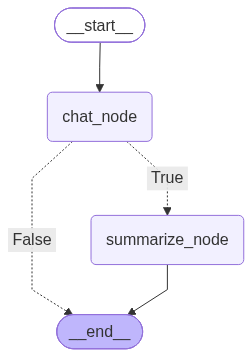

In [223]:
# view graph
Image(workflow.get_graph().draw_mermaid_png())

In [224]:
config = {"configurable": {"thread_id": "thread-1"}}

In [225]:
# initial run
workflow.invoke({"messages": [HumanMessage(content="Hi, I'm Bond. James Bond.")], "summary": ""}, config=config)

def run_turn(input: str):
  return workflow.invoke({"messages": [HumanMessage(content=input)]}, config=config)

--------------------------------------------------------------------------------
HumanMessage : Hi, I'm Bond. James Bond.
--------------------------------------------------------------------------------


In [226]:
def view_state():
  graph_state = workflow.get_state(config)
  values = graph_state.values

  print("-"*35, "STATE", "-"*35)
  print("SUMMARY: ", values.get("summary", "No summary of conversation found."))
  print("NO. OF MESSAGES: ", len(values.get("messages", [])))
  print("MESSAGES:")
  for m in values.get("messages", []):
    print(type(m).__name__, ":", m.content)
  print("-"*80)

In [227]:
run_turn("A 007 agent.")
view_state()

--------------------------------------------------------------------------------
HumanMessage : Hi, I'm Bond. James Bond.
AIMessage : Well, hello, James. What can I do for you?
HumanMessage : A 007 agent.
--------------------------------------------------------------------------------
----------------------------------- STATE -----------------------------------
SUMMARY:  
NO. OF MESSAGES:  4
MESSAGES:
HumanMessage : Hi, I'm Bond. James Bond.
AIMessage : Well, hello, James. What can I do for you?
HumanMessage : A 007 agent.
AIMessage : A distinguished agent, then. What’s the mission?
--------------------------------------------------------------------------------


In [228]:
run_turn("Who work at MI6.")
view_state()

--------------------------------------------------------------------------------
HumanMessage : Hi, I'm Bond. James Bond.
AIMessage : Well, hello, James. What can I do for you?
HumanMessage : A 007 agent.
AIMessage : A distinguished agent, then. What’s the mission?
HumanMessage : Who work at MI6.
--------------------------------------------------------------------------------
----------------------------------- STATE -----------------------------------
SUMMARY:  
NO. OF MESSAGES:  6
MESSAGES:
HumanMessage : Hi, I'm Bond. James Bond.
AIMessage : Well, hello, James. What can I do for you?
HumanMessage : A 007 agent.
AIMessage : A distinguished agent, then. What’s the mission?
HumanMessage : Who work at MI6.
AIMessage : Right—007, an MI6 agent. What’s the mission?
--------------------------------------------------------------------------------


In [229]:
run_turn("Do you know what MI6 agents do?")
view_state()

--------------------------------------------------------------------------------
HumanMessage : Hi, I'm Bond. James Bond.
AIMessage : Well, hello, James. What can I do for you?
HumanMessage : A 007 agent.
AIMessage : A distinguished agent, then. What’s the mission?
HumanMessage : Who work at MI6.
AIMessage : Right—007, an MI6 agent. What’s the mission?
HumanMessage : Do you know what MI6 agents do?
--------------------------------------------------------------------------------
----------------------------------- STATE -----------------------------------
SUMMARY:  
NO. OF MESSAGES:  8
MESSAGES:
HumanMessage : Hi, I'm Bond. James Bond.
AIMessage : Well, hello, James. What can I do for you?
HumanMessage : A 007 agent.
AIMessage : A distinguished agent, then. What’s the mission?
HumanMessage : Who work at MI6.
AIMessage : Right—007, an MI6 agent. What’s the mission?
HumanMessage : Do you know what MI6 agents do?
AIMessage : Yes. MI6—the UK’s Secret Intelligence Service—collects and assess

In [230]:
run_turn("What's the hierarchy of MI6 organization?")
view_state()

--------------------------------------------------------------------------------
HumanMessage : Hi, I'm Bond. James Bond.
AIMessage : Well, hello, James. What can I do for you?
HumanMessage : A 007 agent.
AIMessage : A distinguished agent, then. What’s the mission?
HumanMessage : Who work at MI6.
AIMessage : Right—007, an MI6 agent. What’s the mission?
HumanMessage : Do you know what MI6 agents do?
AIMessage : Yes. MI6—the UK’s Secret Intelligence Service—collects and assesses intelligence from outside the UK to help protect the country’s national security. Its officers may work with people who can provide information, analyze intelligence, and support government decisions.

The real work is usually discreet and collaborative, not like James Bond’s movie adventures. Bond is fictional.
HumanMessage : What's the hierarchy of MI6 organization?
--------------------------------------------------------------------------------
----------------------------------- STATE ------------------------

In [231]:
run_turn("How does the MI6 organization operate?")
view_state()

--------------------------------------------------------------------------------
HumanMessage : Hi, I'm Bond. James Bond.
AIMessage : Well, hello, James. What can I do for you?
HumanMessage : A 007 agent.
AIMessage : A distinguished agent, then. What’s the mission?
HumanMessage : Who work at MI6.
AIMessage : Right—007, an MI6 agent. What’s the mission?
HumanMessage : Do you know what MI6 agents do?
AIMessage : Yes. MI6—the UK’s Secret Intelligence Service—collects and assesses intelligence from outside the UK to help protect the country’s national security. Its officers may work with people who can provide information, analyze intelligence, and support government decisions.

The real work is usually discreet and collaborative, not like James Bond’s movie adventures. Bond is fictional.
HumanMessage : What's the hierarchy of MI6 organization?
AIMessage : MI6’s detailed organizational chart isn’t public, but the broad leadership structure is known:

- **Chief (“C”)** — leads the Secret In

In [232]:
run_turn("Who am i?")
view_state()

--------------------------------------------------------------------------------
SystemMessage : Conversation summary:
You introduced yourself as “James Bond,” a 007 agent working at MI6. I explained that Bond is fictional and described MI6’s public role: gathering and assessing intelligence overseas to support UK national security. I also outlined MI6’s broad, non-public organizational structure and how it works with government and other agencies under legal and independent oversight.
HumanMessage : How does the MI6 organization operate?
AIMessage : At a high level, MI6 (the Secret Intelligence Service, or SIS) works roughly like this:

1. **The government sets intelligence priorities** based on national-security and foreign-policy needs.
2. **MI6 collects intelligence overseas** using human sources and other methods authorized by law.
3. **Specialists assess and verify information**, often combining it with reporting from other agencies and open sources.
4. **Findings are shared** wi